# **추천 시스템**

<p align="right">15기 손영현</p>

---

## **<span style="background-color:#FCE4EC;">1. 추천 시스템 기초</span>**

### **<span style="background-color:#E3F2FD;">1.1 추천 시스템과 데이터 유형</span>**

1) 추천 시스템이란?
- 개념: 사용자의 행동 기록과 아이템 정보를 바탕으로 <mark style="background-color:#CFEFFF; color:#000000">사용자가 좋아할 만한 아이템을 예측해 골라 주는 시스템</mark>
- 검색은 이미 아는 걸 찾게 돕고, 추천은 아직 모르는 걸 발견하게 도움.
- 기업 입장에선 이용 시간, 구매 전환이 늘고 비인기 아이템(롱테일)도 노출할 수 있음.

2) 데이터 유형
- 명시적 데이터: 사용자가 선호를 직접 표현 (별점, 좋아요, 리뷰). 취향이 분명하지만 평가 남기는 사람이 적고 기준도 사람마다 다름.
- 암시적 데이터: 행동에서 선호를 추측 (클릭, 구매, 시청 시간). 많이 쌓이지만 행동이 곧 선호는 아님 (잘못 클릭, 선물 구매, 아직 못 봄)
- 실제로는 암시적 데이터가 훨씬 많아서 둘을 섞어 씀.

### **<span style="background-color:#E3F2FD;">1.2 추천 시스템 분류</span>**

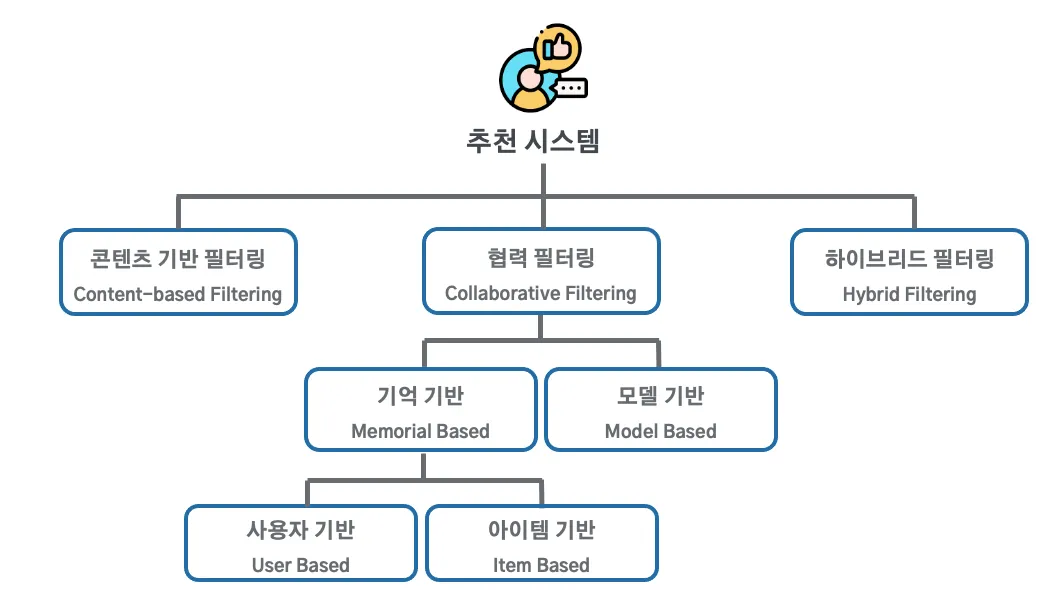

1) 내용 기반 필터링: <mark style="background-color:#CFEFFF; color:#000000">내가 고른 아이템과 특징이 비슷한 아이템</mark> 추천 (SF 영화를 자주 봄 → 다른 SF 영화)

2) 협업 필터링: <mark style="background-color:#CFEFFF; color:#000000">다수 사용자의 선호 패턴</mark>을 근거로 추천
- 사용자 기반: 나와 비슷한 사용자가 좋아한 아이템 추천 (A와 B가 라면, 콜라를 같이 삼 → A가 산 생수를 B에게)
- 아이템 기반: 같이 선호되는 패턴이 비슷한 아이템 추천 (콜라 산 사람들이 생수도 많이 삼 → 콜라 좋아하는 B에게 생수)

3) 하이브리드: 여러 알고리즘을 조합해서 단점을 보완
- Weighted Ensemble, Mixed, Switch, Feature Combination, Meta-Level 방식이 있음.
- ex. 새 영화는 평점이 없으니 장르·감독으로 내용 기반 추천 → 평점이 쌓이면 협업 필터링으로 (Switch)

---

## **<span style="background-color:#FCE4EC;">2. 내용 기반 필터링</span>**

[아이템을 숫자로 표현 → 사용자 프로필 생성 → 유사도 계산 → 점수 높은 아이템 추천]

### **<span style="background-color:#E3F2FD;">2.1 사용자 프로필과 유사도</span>**

1) 사용자 프로필
- 사용자가 어떤 특성을 좋아하는지 정리한 정보
- 만드는 방법
    1. 본 아이템들의 특성 벡터를 평균냄. ex. 어벤져스, 인터스텔라, 노트북 평균 → [액션 0.4, 로맨스 0.4, SF 0.47, 공포 0.03] → 새 영화 듄과 코사인 유사도 약 0.8이라 추천
    2. 설문, 평점, 검색·구매 기록으로 따로 파악
    3. 아이템 특징을 입력, 기존 평가를 정답으로 놓고 분류 문제로 풂

2) 유사도
- 개념: <mark style="background-color:#CFEFFF; color:#000000">두 대상이 얼마나 비슷한지 나타내는 숫자</mark>
- 아이템을 feature로 원-핫 인코딩하고, 사용자도 같은 feature로 표현해야 비교할 수 있음.
- 종류: 자카드(교집합), 코사인(각도), 유클리드(거리), 피어슨(선형 상관)
- 코사인 유사도: $\cos\theta = \dfrac{A \cdot B}{\|A\| \|B\|}$ → 길이는 무시하고 방향만 봄.
- 내적은 feature가 많은 아이템이 유리해지고, 코사인은 그 쏠림이 없음.

3) TF-IDF
- <mark style="background-color:#CFEFFF; color:#000000">그 문서에는 자주 나오고 다른 문서에는 드문 단어</mark>에 높은 값을 줌.
- TF: 문서 안 등장 횟수 / IDF: $\log\dfrac{n}{1 + df(t)}$ (여러 문서에 나올수록 작아짐)
- ex. '귀엽다'처럼 여러 문서에 나오면 IDF가 0에 가까워 중요도가 낮음.
- 추천에선 줄거리를 TF-IDF 벡터로 바꾸고 코사인 유사도로 비슷한 영화를 찾음.

### **<span style="background-color:#E3F2FD;">2.2 장단점</span>**

- 장점: 속성만 있으면 새 아이템도 추천 가능 (<mark style="background-color:#CFEFFF; color:#000000">아이템 콜드 스타트 해결</mark>), 다른 사용자 데이터 필요 없음, 추천 이유 설명이 쉬움.
- 단점: feature 품질에 따라 정확도가 갈림, 비슷한 것만 계속 추천함(Over-specialization), 신규 사용자는 여전히 어려움.

---

## **<span style="background-color:#FCE4EC;">3. 협업 필터링</span>**

[가정: 과거에 취향이 비슷했던 사람들은 앞으로도 비슷할 것이다]

### **<span style="background-color:#E3F2FD;">3.1 메모리 기반 협업 필터링</span>**

1) 개념
- 저장된 평점을 <mark style="background-color:#CFEFFF; color:#000000">그대로 꺼내서 비슷한 이웃을 찾아</mark> 예측하는 방법 (이웃 기반 CF)

2) 사용자 기반
- 나와 비슷한 사용자 Top-N의 평점을 유사도로 가중평균해서 예측 (평점 데이터에선 피어슨 상관계수를 많이 씀)
- $\hat{r}_{ui} = \bar{r}_u + \dfrac{\sum_v sim(u,v)(r_{vi} - \bar{r}_v)}{\sum_v |sim(u,v)|}$
- ex. A와 B는 sim 0.97, A와 C는 −1 → B가 라라랜드를 평균보다 높게, C가 낮게 줬으니 A의 예측은 약 3.96 → 추천

3) 아이템 기반
- 내가 평가한 아이템과 평점 패턴이 비슷한 아이템을 추천 (어바웃 타임 높게 준 사람이 노팅힐도 높게 줌 → 비슷한 아이템)
- 아이템 관계는 잘 안 변해서 유사도를 미리 계산해 두고 재사용하기 좋음.

4) 비교
| 기준 | 사용자 기반 | 아이템 기반 |
|---|---|---|
| 유리한 상황 | 아이템 수 > 사용자 수 | 사용자 수 > 아이템 수 |
| 속도 | 추천할 때마다 이웃을 새로 찾음 | 미리 계산해 둬서 빠름 |
| 다양성 | 의외성, 참신성 | 본 것과 비슷한 추천 위주 |
| 예 | 뉴스, SNS 친구 추천 | 아마존 같은 대형 플랫폼 |

### **<span style="background-color:#E3F2FD;">3.2 메모리 기반 협업 필터링의 한계</span>**

1) 희소 행렬: 넷플릭스 프라이즈 데이터는 <mark style="background-color:#CFEFFF; color:#000000">99%가 빈칸</mark>이라 같이 평가한 아이템이 적어 유사도를 믿기 어려움. → 모델 기반 CF로 해결

2) 콜드 스타트: 기록이 없는 신규 사용자는 이웃을 못 찾고, 신규 아이템은 후보에 못 오름(first-rater 문제). → 가입할 때 취향 고르기, 내용 기반과 섞기, 인구통계 정보 활용

3) 확장성: 사용자와 아이템이 늘수록 계산량이 커짐. → KNN CF로 유사도 높은 k명만 사용 (k가 너무 작으면 흔들리고 너무 크면 흐려짐)

### **<span style="background-color:#E3F2FD;">3.3 모델 기반 협업 필터링</span>**

1) 개념
- 관측된 평점으로 <mark style="background-color:#CFEFFF; color:#000000">예측 모델을 먼저 학습</mark>하고, 그 모델로 빈칸을 예측하는 방법
- 학습은 미리 해 두고 추천할 땐 빠르게 계산함. 겹치는 평가가 없어도 전체 패턴으로 빈칸을 채움.

2) 잠재 요인
- 평점에 드러나지 않는 숨은 특성(취향 같은 것)을 숫자로 표현한 것
- 축 개수 k만 정하고 의미는 학습으로 정해져서 해석하기 어려움. 사용자와 아이템을 같은 공간의 벡터로 놓음.

3) 행렬 분해 (MF)
- 평점 행렬을 <mark style="background-color:#CFEFFF; color:#000000">작은 행렬 두 개의 곱</mark>으로 쪼갬: $\hat{R} = P^T Q$, 예측은 두 벡터의 내적 $\hat{r}_{ui} = p_u^T q_i$

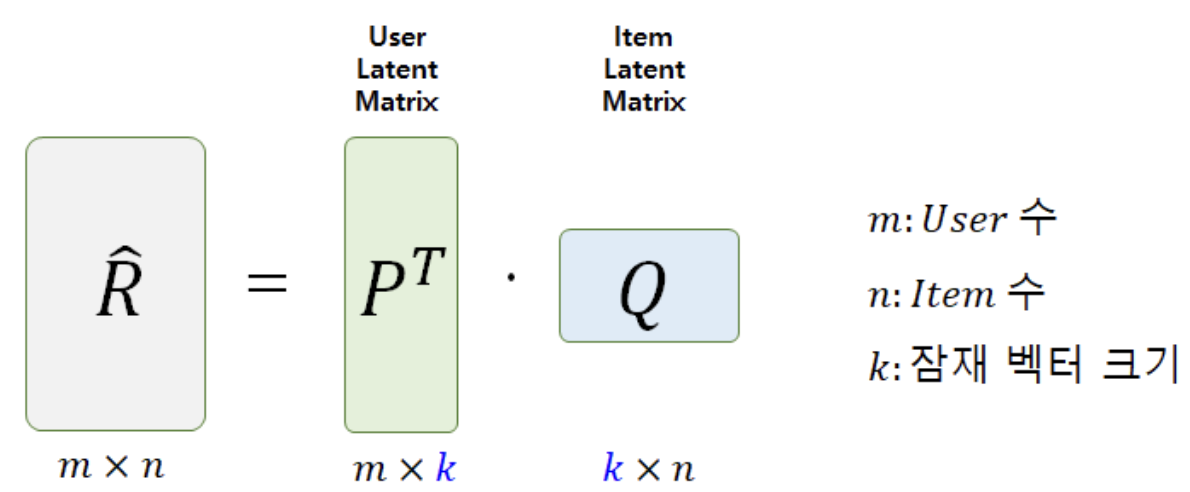

- ex. 사용자 (0.9, 0.2) · 노팅힐 (0.8, 0.1) = 0.74 > 존 윅 (0.1, 0.9) = 0.27 → 노팅힐 추천
- 학습: 평점이 있는 칸만 예측해서 오차를 줄이는 방향으로 수정 (SGD 또는 ALS), 손실에 규제항 λ를 더해 과적합 방지
- 편향 추가: $\hat{r}_{ui} = \mu + b_i + b_u + p_u^T q_i$ → 깐깐한 사람, 평이 좋은 영화 같은 경향을 따로 빼 줌.

4) 정리
- 메모리 기반보다 빠르고 일반화에 유리하지만, 콜드 스타트는 여전하고 <mark style="background-color:#CFEFFF; color:#000000">내적이라는 선형 계산</mark>의 한계가 남음 → 딥러닝으로 넘어감

---

## **<span style="background-color:#FCE4EC;">4. VAE 기반 협업 필터링</span>**

### **<span style="background-color:#E3F2FD;">4.1 MF의 한계와 VAE 구조</span>**

1) MF의 한계
- 선형성: 요인별로 곱해서 더하기만 해서 요인끼리 얽히는 효과를 못 표현함 (로맨스, 음악 영화는 좋은데 뮤지컬 로맨스는 싫은 사람)
- 불확실성 무시: 기록 5개인 사람과 5,000개인 사람을 벡터 하나로 똑같이 확신함 (점 추정)
- → 비선형 신경망 + 평균과 분산을 같이 출력하는 VAE로 해결

2) AE vs VAE
- AE: 입력을 작게 압축했다가 복원하는 신경망. 근데 사용자를 여전히 점 하나로 표현함.
- VAE: 잠재 벡터를 <mark style="background-color:#CFEFFF; color:#000000">분포(평균 μ, 표준편차 σ)로 표현</mark>하는 오토인코더
    - μ는 취향의 중심, σ는 얼마나 확신 못 하는지
    - μ 주변에서 z를 샘플링해서 학습하니까 기록이 적어도 노이즈에 덜 흔들림.

3) Mult-VAE 구조
- 입력(0/1 상호작용 벡터) → 인코더(μ, σ) → 샘플링(z) → 디코더(모든 아이템 점수 → softmax 확률)

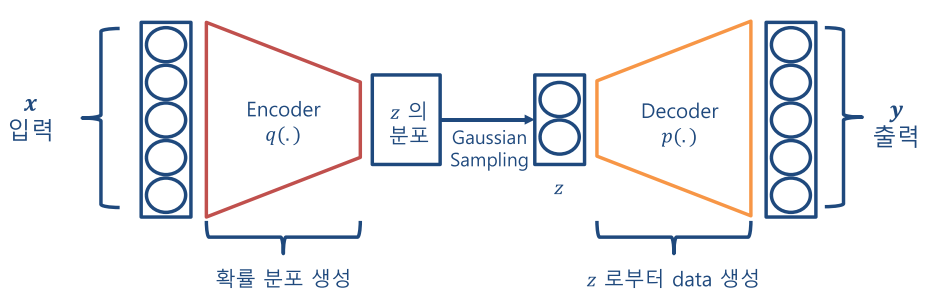

- 확률이 높은 순서로 아직 안 본 아이템을 추천

### **<span style="background-color:#E3F2FD;">4.2 목적 함수와 KL Divergence</span>**

1) ELBO
- $\mathcal{L} = E_{q(z|x)}[\log p(x|z)] - D_{KL}(q(z|x) \| p(z))$
- 복원 항: 원래 입력을 최대한 비슷하게 복원
- KL 항: 잠재 분포가 표준 정규분포에서 많이 벗어나지 않게 해서 과적합을 막음.
- 시험으로 치면 복원은 '기출 많이 풀기', KL은 '기본 개념에서 벗어나지 않기'

2) KL Divergence
- 개념: <mark style="background-color:#CFEFFF; color:#000000">두 확률분포가 얼마나 다른지</mark> 나타내는 값
- 중심에서 멀어지거나(μ ↑), 너무 확신하거나(σ ↓), 너무 퍼지면(σ ↑) 벌점이 커짐.

3) KL 항의 효과
- AE는 벡터가 듬성듬성 흩어지지만, VAE는 분포들이 중심 근처에 연속적으로 모임.
- 기록 적은 사용자도 비슷한 사용자들 근처에 놓여서 <mark style="background-color:#CFEFFF; color:#000000">희소한 데이터에 강함</mark>

---

## **<span style="background-color:#FCE4EC;">5. GNN 기반 사용자 선호 예측</span>**

[CF, MF, VAE는 상호작용을 행렬 칸 하나하나로 봐서 이어진 관계를 직접 못 씀]

### **<span style="background-color:#E3F2FD;">5.1 GNN 구조와 프로세스</span>**

1) 왜 그래프인가
- 사용자·아이템은 노드, 봤다·샀다는 엣지 → 행렬의 칸 하나가 그래프에선 경로가 됨 (나 → 영화 X → X를 본 사람 → 영화 Y)
- 그래프는 노드마다 이웃 수가 다르고 순서·좌표가 없어서(Non-Euclidean) CNN, RNN 대신 GNN이 필요함.

2) GNN 작동 구조
- 핵심 아이디어: <mark style="background-color:#CFEFFF; color:#000000">이웃 노드의 정보를 나에게 전달하고 요약하는 것 (Message Passing)</mark>
- 그래프 구조 생성: 노드·엣지 정의하고 초기 임베딩 부여 (인접 행렬, 피처 행렬로도 표현 가능)
- 메시지 패싱 (레이어 하나 = 3단계)
    1. 메시지 생성: 이웃 노드가 자기 임베딩으로 메시지를 만듦.
    2. 집계: 받은 메시지를 하나로 합침 (sum, mean, max, attention)
    3. 갱신: 집계 결과와 자기 이전 임베딩을 합쳐 새 임베딩 계산
- 레이어를 K번 쌓으면 K단계 떨어진 이웃까지 반영됨.

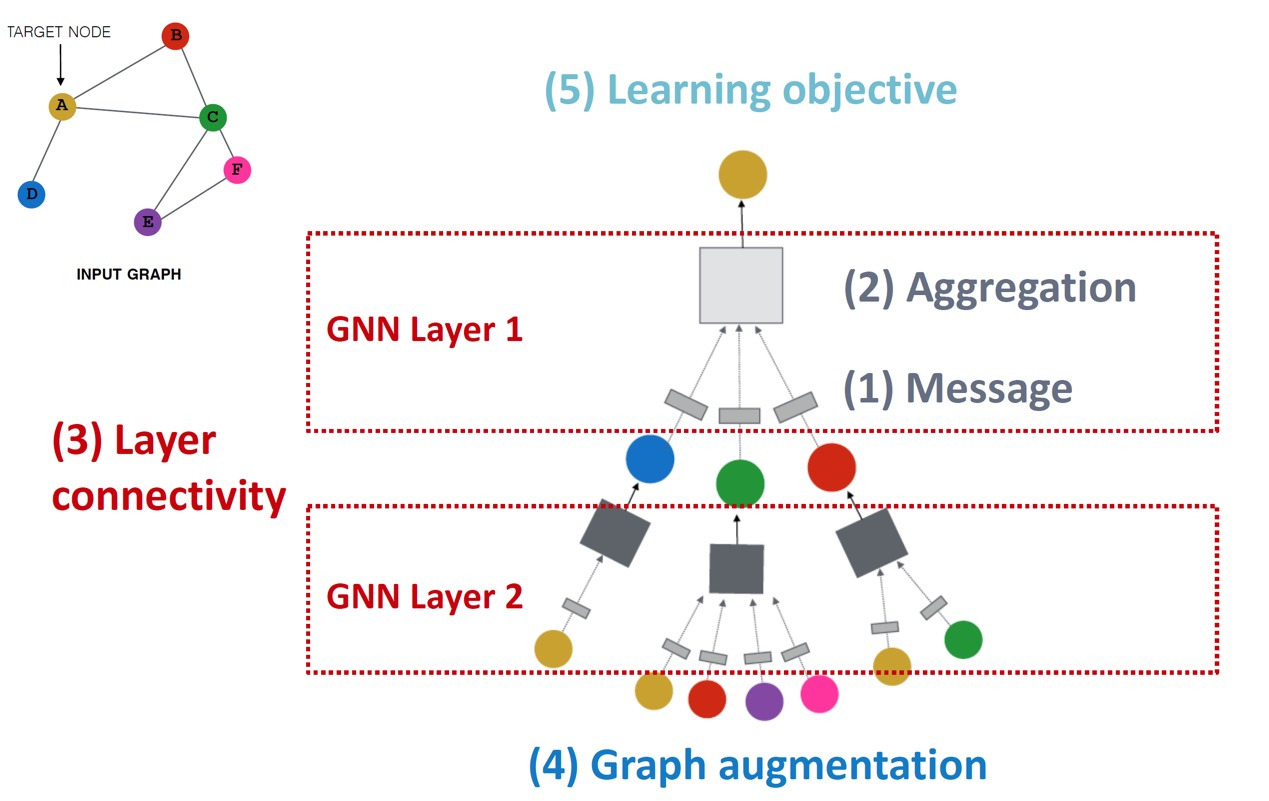

### **<span style="background-color:#E3F2FD;">5.2 LightGCN</span>**

1) 주요 GNN 아키텍처
| 아키텍처 | 방식 | 특징 |
|---|---|---|
| GCN | 이웃 임베딩을 정규화해서 평균 | 가장 기본 |
| GRN | RNN + GNN | 시간에 따라 변하는 그래프 |
| GAT | attention으로 이웃별 중요도를 학습 | 중요한 이웃에 집중 |
| GraphSAGE | 이웃 일부만 샘플링, concat | 대규모 그래프, 새 노드에도 적용 |

- 추천에선 GCN 계열이 많이 쓰임: NGCF(2019) → 단순화한 LightGCN(2020)

2) LightGCN
- 추천 그래프 노드엔 <mark style="background-color:#CFEFFF; color:#000000">ID 임베딩만 있어서</mark> NGCF의 가중치 행렬 W와 비선형 활성화 함수가 도움이 안 되고 오히려 학습을 방해함.
- 그래서 특징 변환(W)과 비선형 활성화를 제거하고, 정규화된 이웃 임베딩의 합만 남김.

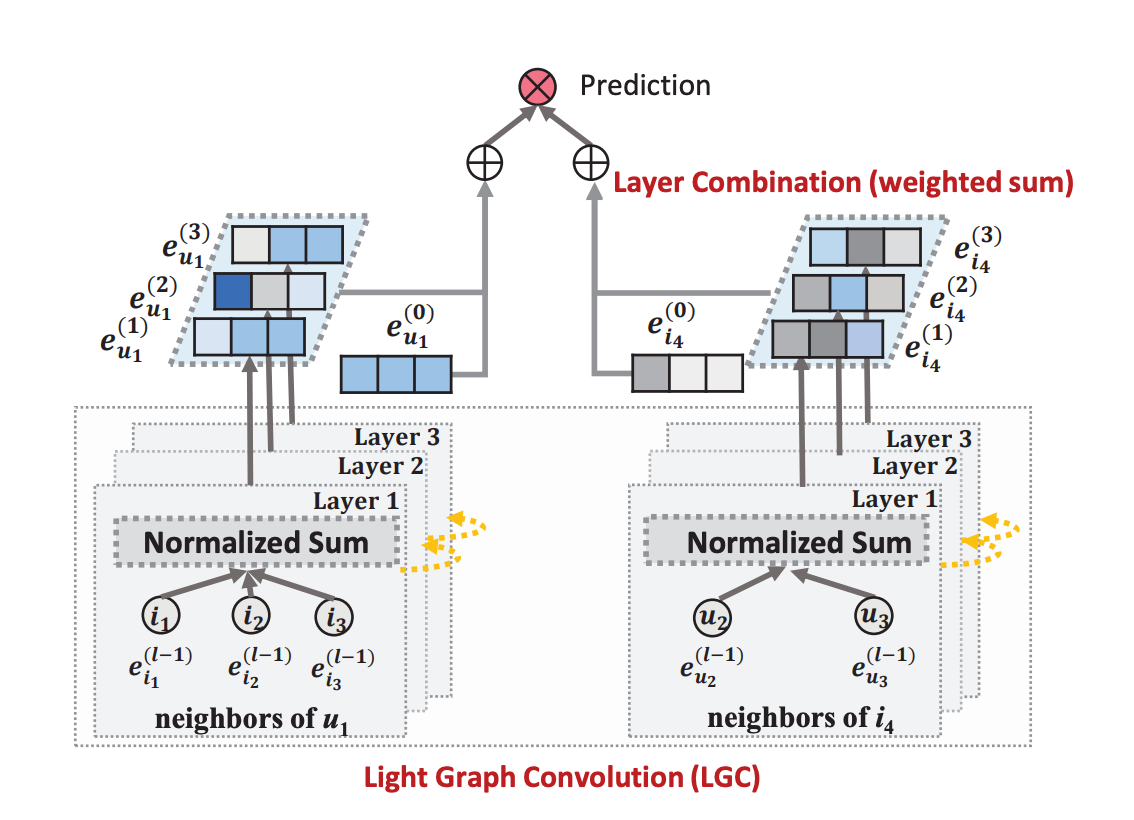

- 더 가벼운데 NGCF보다 평균 약 16% 성능이 높았음.

### **<span style="background-color:#E3F2FD;">5.3 GNN 활용 사례 및 장단점</span>**

1) 활용 사례
- Pinterest: 핀과 보드를 노드로 한 그래프 (노드 약 30억 개). 규모가 커서 GraphSAGE처럼 이웃 일부만 샘플링해서 학습함.
- 그 외: 친구 추천, 분자 구조 분석, 이상 거래 탐지, 교통 예측

2) 장점
- 비슷한 사용자, 연관 아이템 정보까지 반복해서 반영 (고차원 협업 시그널)
- 소셜 관계, 속성 등 여러 정보를 한 그래프에 담을 수 있음.
- 신규 아이템도 이웃·속성 정보로 임베딩을 얻을 수 있어서 콜드 스타트 완화

3) 단점
- 과평탄화: 레이어가 많아질수록 모든 노드 임베딩이 비슷해짐.
- 과압축: 늘어나는 이웃 정보를 고정 크기 벡터에 담다 보니 먼 정보가 손실됨.
- 계산량이 크고, 순서를 반영 못 함 (신발 → 바지 → 셔츠와 반대 순서가 같은 그래프)

---

## **<span style="background-color:#FCE4EC;">6. Transformer 기반 추천 시스템</span>**

### **<span style="background-color:#E3F2FD;">6.1 기존 추천 시스템의 한계</span>**

- CF: 구매 순서가 달라도 같은 사용자로 보고, 방금 한 구매와 1년 전 구매를 구분 못 함.
- GNN: [A → B → C]에서 C가 A 정보를 받으려면 B를 거쳐야 해서 희석되고, 멀리 떨어진 행동 관계를 잡기 어려움.
- 둘 다 <mark style="background-color:#CFEFFF; color:#000000">'어떤 순서로, 지금 어떤 의도로'</mark> 행동하는지는 못 봄 → Transformer 등장

### **<span style="background-color:#E3F2FD;">6.2 Transformer와 Transformer 기반 주요 추천 시스템 모델</span>**

1) 행동을 시퀀스로 보기
- 다음 행동은 평균 취향보다 <mark style="background-color:#CFEFFF; color:#000000">최근 행동의 순서와 조합(문맥)</mark>에 더 영향을 받음.
- 수영복 → 비치타월 → 선크림이면 휴가 준비물(방수팩 추천), 스킨 → 로션 → 선크림이면 스킨케어(클렌징폼 추천)
- 프린터 → 양말 → 라면 → … → ? 처럼 사이에 관련 없는 행동이 많아도 프린터에 집중해서 토너를 추천함.

2) Self-Attention
- 시퀀스 안의 <mark style="background-color:#CFEFFF; color:#000000">모든 아이템 쌍의 관련성을 거리와 상관없이 한 번에 계산</mark>
- Query(관련성을 계산하는 기준), Key(Query와 내적해서 점수 결정), Value(가중합되는 실제 정보)
- $\text{Attention}(Q, K, V) = \text{softmax}\left(\dfrac{QK^T}{\sqrt{d}}\right)V$
- ex. 선크림 기준 수영복 57%, 비치타월 34.5%, 양말 8.5% → 휴가 준비물로 해석

3) SASRec vs BERT4Rec
| 구분 | SASRec | BERT4Rec |
|---|---|---|
| 어텐션 방향 | 단방향 (과거만, GPT 같음) | 양방향 (앞뒤 모두, BERT 같음) |
| 학습 목표 | 다음 아이템 예측 | [MASK]로 가린 아이템 예측 |
| 학습 효율 | 빠름 | 상대적으로 느림 |

- SASRec은 병렬 처리라 빠르지만 연산량이 시퀀스 길이의 제곱에 비례하고 과거만 봄.

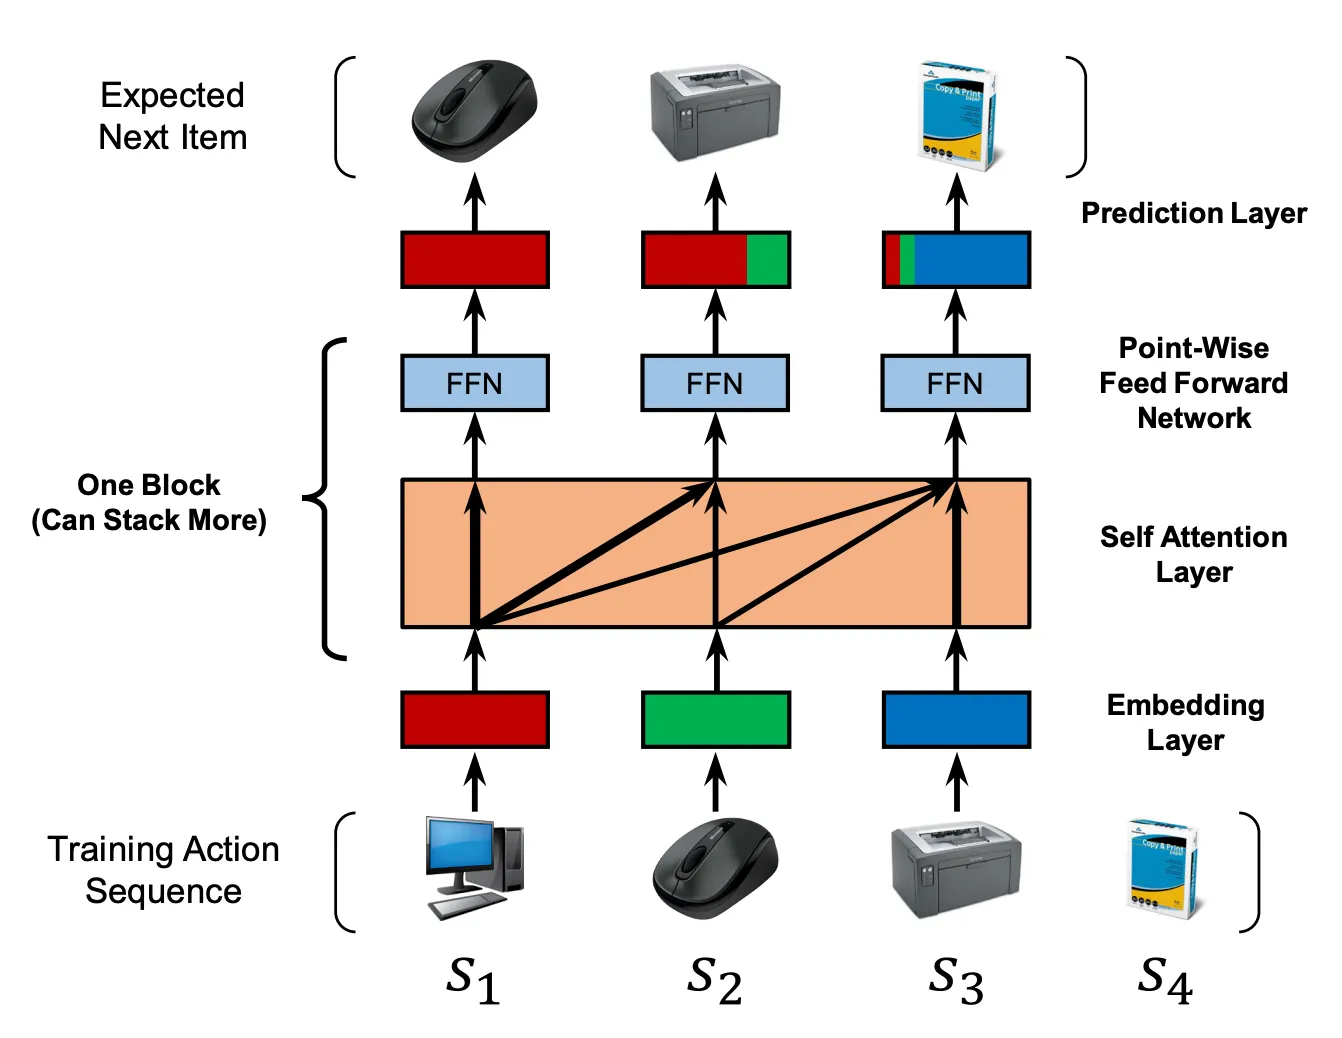

- BERT4Rec은 정보 누출을 막으려고 [MASK]로 가리고, 가리는 위치를 바꿔 가며 샘플을 여러 개 만들 수 있음.

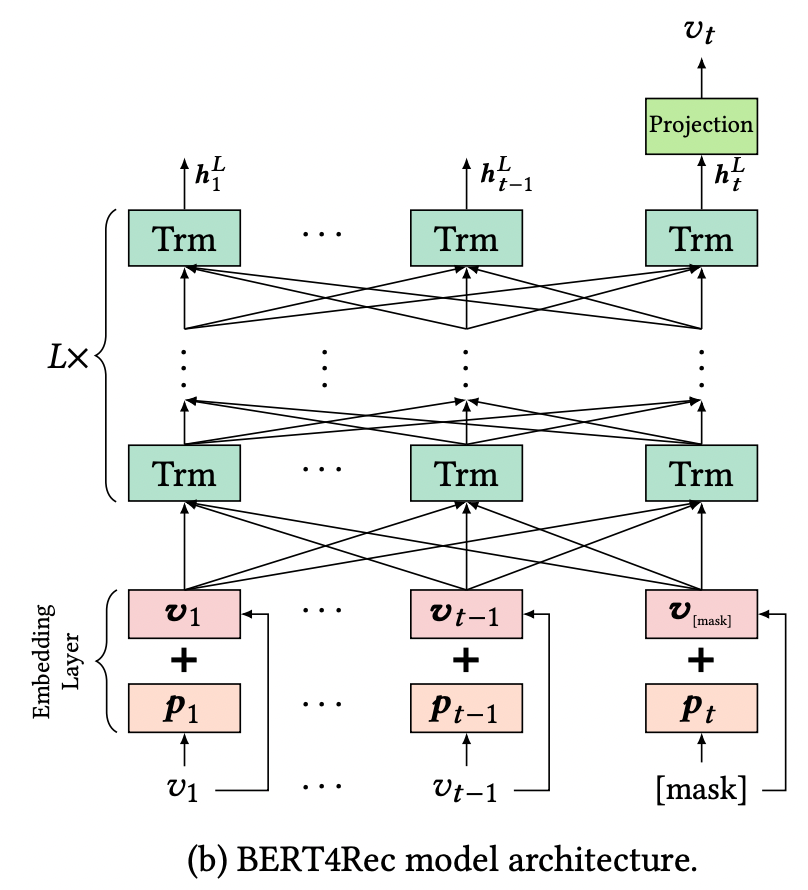

- 후속 연구에서 손실 함수를 맞추니 SASRec이 비슷하거나 더 좋았음 → 성능 차이는 학습 설정 영향이 컸고, 상황에 따라 고름.

---

## **<span style="background-color:#FCE4EC;">7. 오늘날의 추천 시스템</span>**

1) LLM의 시대
- 추천을 점수 계산이 아니라 <mark style="background-color:#CFEFFF; color:#000000">언어 문제로 푸는 방향</mark>으로 바뀌는 중 → 추천 이유까지 문장으로 줄 수 있음.
- 대화형 추천("비 오는 일요일에 혼자 보기 좋은 영화")과 zero-shot 추천(설명만으로 신상품 추천 → 콜드 스타트 해결)이 가능해짐.
- P5: 여러 추천 과제를 텍스트 형식으로 통일해서 처음부터 학습 / TALLRec: 범용 LLM을 Yes/No 지시문으로 LoRA 튜닝

2) 인기 편향과 XAI
- 인기 편향: 인기 아이템이 추천을 독점하고, 추천 → 노출 → 클릭 → 학습이 반복되며 격차가 커짐 (넷플릭스 프라이즈: 인기 영화 16.5%가 평점의 86%)
- XAI: 딥러닝은 블랙박스라 추천 이유를 설명하기 어려움. LLM이 설명을 만들어도 <mark style="background-color:#CFEFFF; color:#000000">실제 근거와 같다는 보장은 없음</mark>

3) 비용을 고려한 2단계 구조
- 딥러닝을 전부 적용하기엔 GPU, 서버 비용이 너무 큼.
- 후보군 생성(수백만 → 수백 개)은 선형 모델(내용 기반, CF, MF)로 빠르게, 순위 매기기(수백 → 수십 개)는 딥러닝(GNN, Transformer, VAE)으로 정교하게

---

## **<span style="background-color:#FCE4EC;">8. 정리</span>**

- 내용 기반: 속성이 비슷한 걸 추천 → 새 아이템엔 강하지만 비슷한 것만 추천함
- 메모리 기반 CF: 이웃을 직접 찾음 → 희소성, 콜드 스타트, 확장성 문제
- 모델 기반 CF(MF): 잠재 요인 벡터의 내적으로 예측 → 빠르지만 선형이고 불확실성을 무시함
- VAE: 비선형 + 분포로 사용자 표현 → 희소한 데이터에 강함
- GNN(LightGCN): 그래프로 이웃 정보 전달 → 관계는 잘 보지만 순서는 못 봄
- Transformer(SASRec, BERT4Rec): Self-Attention으로 순서와 지금 맥락을 반영
- 요즘: LLM 기반 추천, 인기 편향·설명 가능성 문제, 선형 모델로 거르고 딥러닝으로 정렬하는 2단계 구조